# 02 · Statistical Analysis - Regression and Trend Detection

**Two questions, answered with methods that respect the time-series nature of the data:**

1. **What explains river discharge?** Multiple linear regression, but with (a) *lagged* rainfall, (b) *robust (HAC / Newey-West) standard errors* and (c) a multicollinearity check because ordinary OLS p-values are over-confident when residuals are autocorrelated, which they always are for monthly river flow.
2. **Is the climate of this catchment changing?** Parametric (OLS) and non-parametric (Mann-Kendall, Theil-Sen) trend tests, plus the *Hamed-Rao* correction for autocorrelation, the *seasonal* Mann-Kendall test, and a Holm correction for testing four variables at once.

> ⚠️ **Requires** `statsmodels` and `pymannkendall` (`pip install -r requirements.txt`). Regression here is **explanatory** (in-sample). Out-of-sample forecasting is in notebooks 03 and 04.

In [2]:
import sys, warnings
sys.path.append("../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.multitest import multipletests
from scipy.stats import linregress, theilslopes
import pymannkendall as mk

import kodumudi as kd

plt.style.use("seaborn-v0_8-whitegrid")
FIG_DIR, TAB_DIR = "../reports/figures", "../reports/tables"
def save_fig(name): plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

daily   = kd.load_daily()
monthly = kd.aggregate(daily, "MS")
annual  = kd.aggregate(daily, "YS")
print(len(daily), len(monthly), len(annual))

13149 432 36


## 1 · Regression: what drives discharge?

### 1.1 Helper - OLS with robust standard errors
* **HAC (Newey-West) standard errors** correct the p-values for autocorrelated residuals. `maxlags` = how many lags of autocorrelation to allow for (12 for monthly data, 3 for annual).
* **Durbin-Watson** statistic: ≈ 2 means no residual autocorrelation; values well below 2 mean strong positive autocorrelation (OLS p-values would be too optimistic).

In [3]:
def fit_ols(df, y, xs, maxlags, standardize=False):
    d = df[[y] + xs].dropna()
    if standardize:                       # z-scores -> coefficients become comparable effect sizes
        d = (d - d.mean()) / d.std()
    res = sm.OLS(d[y], sm.add_constant(d[xs])).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    return res

def summarize(res, name):
    return {"model": name, "n": int(res.nobs), "R2": res.rsquared, "Adj R2": res.rsquared_adj,
            "AIC": res.aic, "Durbin-Watson": durbin_watson(res.resid)}

TARGET = "discharge_m3s"
base = ["rainfall_mm", "temperature_c", "soil_moisture_kgm2"]

### 1.2 Does the time scale change the answer?
Same model (discharge ~ rainfall + temperature + soil moisture, all in the same period) at daily, monthly and annual resolution.

In [4]:
scales = {"Daily": (daily, 30), "Monthly": (monthly, 12), "Annual": (annual, 3)}
rows = []
for name, (df, lags) in scales.items():
    res = fit_ols(df, TARGET, base, maxlags=lags)
    rows.append(summarize(res, name))
pd.DataFrame(rows).set_index("model").round(3)

,n,R2,Adj R2,AIC,Durbin-Watson
model,,,,,
Daily,13149,0.247,0.247,170909.033,0.136
Monthly,432,0.505,0.501,5213.091,1.363
Annual,36,0.583,0.544,356.895,1.461


### 1.3 Adding the lag structure found in EDA (monthly scale)
Notebook 01 showed that rainfall affects *next month's* flow more than this month's. We add rainfall lagged 1 and 2 months (M2) and then month-of-year seasonality as sine/cosine terms (M3).

In [5]:
m = monthly.copy()
m["rain_lag1"] = m["rainfall_mm"].shift(1)
m["rain_lag2"] = m["rainfall_mm"].shift(2)
m["sin12"] = np.sin(2 * np.pi * m.index.month / 12)
m["cos12"] = np.cos(2 * np.pi * m.index.month / 12)

specs = {
    "M1: contemporaneous":          base,
    "M2: + lagged rainfall":        base + ["rain_lag1", "rain_lag2"],
    "M3: + seasonality (sin/cos)":  base + ["rain_lag1", "rain_lag2", "sin12", "cos12"],
}
# Fit every model on the SAME rows (first two months lack lags) so AIC/R² are comparable
m_cmp = m.dropna(subset=["rain_lag1", "rain_lag2"])
fits = {k: fit_ols(m_cmp, TARGET, v, maxlags=12) for k, v in specs.items()}
comparison = pd.DataFrame([summarize(r, k) for k, r in fits.items()]).set_index("model")
comparison.round(3)

,n,R2,Adj R2,AIC,Durbin-Watson
model,,,,,
M1: contemporaneous,430,0.504,0.501,5190.884,1.363
M2: + lagged rainfall,430,0.656,0.652,5037.670,1.522
M3: + seasonality (sin/cos),430,0.669,0.663,5025.809,1.527


**How to read this:** compare Adj R² (higher = better, penalised for extra terms), AIC (lower = better) and Durbin-Watson (closer to 2 = less leftover autocorrelation). All three models are fitted on the *same* rows (the first two months, which lack lags, are dropped for every model), so AIC is directly comparable.

In [6]:
# Coefficient table for the richest model, with robust (HAC) standard errors
res = fits["M3: + seasonality (sin/cos)"]
coef = pd.DataFrame({"coef": res.params, "robust SE": res.bse, "p-value": res.pvalues,
                     "CI low": res.conf_int()[0], "CI high": res.conf_int()[1]})
coef.round(4)

,coef,robust SE,p-value,CI low,CI high
const,718.3237,81.3965,0.0000,558.7896,877.8578
rainfall_mm,0.7089,0.1930,0.0002,0.3306,1.0873
temperature_c,-25.9785,3.3598,0.0000,-32.5637,-19.3934
soil_moisture_kgm2,-2.2761,1.5453,0.1408,-5.3048,0.7526
rain_lag1,0.9760,0.0823,0.0000,0.8148,1.1372
rain_lag2,0.6001,0.1024,0.0000,0.3993,0.8008
sin12,8.3511,11.2888,0.4594,-13.7745,30.4767
cos12,-35.5113,9.0387,0.0001,-53.2268,-17.7957


### 1.4 Multicollinearity check (VIF)
Rainfall, lagged rainfall and soil moisture are physically related. A **Variance Inflation Factor** above ~5 (strict) or ~10 (lenient) means a coefficient is hard to interpret individually, even if the model predicts well.

In [7]:
Xv = sm.add_constant(m_cmp[specs["M2: + lagged rainfall"]])
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
                index=Xv.columns[1:], name="VIF")
vif.round(2).to_frame()

,VIF
rainfall_mm,3.09
temperature_c,1.84
soil_moisture_kgm2,4.39
rain_lag1,2.24
rain_lag2,2.13


### 1.5 Which driver matters most? (standardised coefficients)
After converting every variable to z-scores, a coefficient says "a one-standard-deviation change in this driver moves discharge by *β* standard deviations", so effect sizes are comparable across variables with different units.

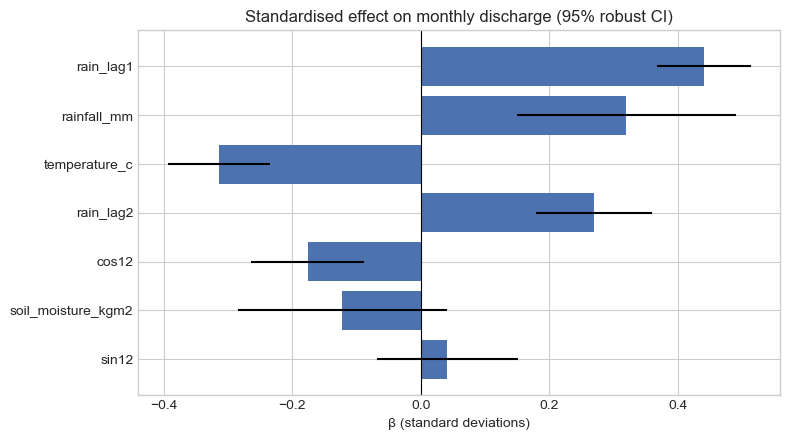

In [8]:
res_std = fit_ols(m_cmp, TARGET, specs["M3: + seasonality (sin/cos)"], maxlags=12, standardize=True)
beta = res_std.params.drop("const")
ci = res_std.conf_int().drop("const")
order = beta.abs().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(order, beta[order], xerr=[beta[order] - ci.loc[order, 0], ci.loc[order, 1] - beta[order]], color="#4c72b0")
ax.axvline(0, color="black", lw=.8)
ax.set(title="Standardised effect on monthly discharge (95% robust CI)", xlabel="β (standard deviations)")
plt.tight_layout(); save_fig("02_standardised_coefficients"); plt.show()

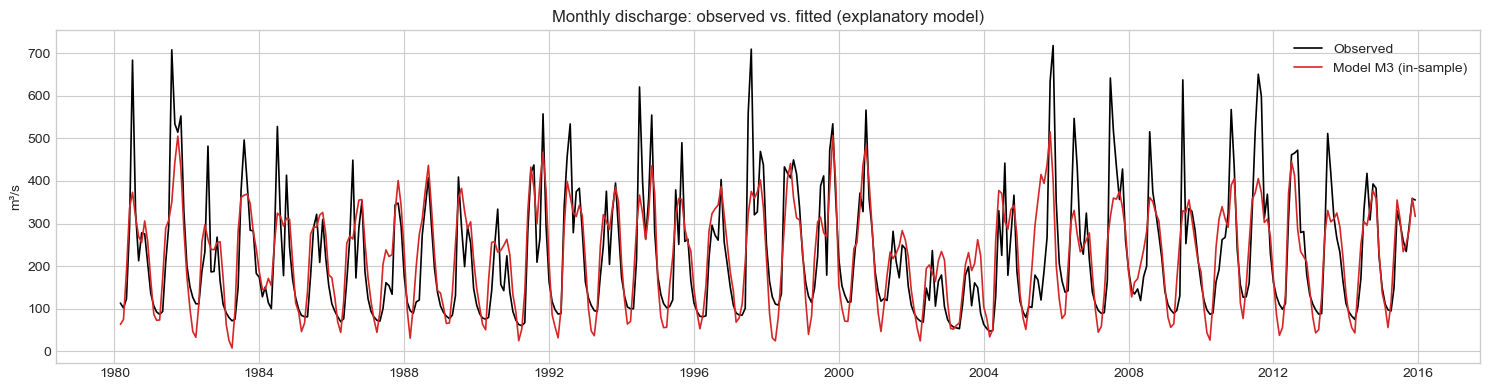

In [9]:
fitted = fits["M3: + seasonality (sin/cos)"].fittedvalues
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(m_cmp.loc[fitted.index, TARGET], color="black", lw=1.2, label="Observed")
ax.plot(fitted, color="#d62728", lw=1.2, label="Model M3 (in-sample)")
ax.set(title="Monthly discharge: observed vs. fitted (explanatory model)", ylabel="m³/s"); ax.legend()
plt.tight_layout(); save_fig("02_regression_fit"); plt.show()

comparison.round(4).to_csv(f"{TAB_DIR}/regression_models.csv", index_label="model")
coef.round(5).to_csv(f"{TAB_DIR}/regression_m3_coefficients.csv", index_label="term")

## 2 · Trend analysis (annual scale)

| Test | Type | Notes |
|---|---|---|
| **OLS slope** | parametric | assumes normal, independent residuals; sensitive to outliers |
| **Theil-Sen slope** | non-parametric | median of all pairwise slopes; robust to outliers; we report a 95 % CI |
| **Mann-Kendall (MK)** | non-parametric | tests for a monotonic trend using ranks |
| **Hamed-Rao modified MK** | non-parametric | MK corrected for autocorrelation (plain MK over-rejects when data are autocorrelated) |
| **Seasonal MK** | non-parametric | runs MK within each calendar month and combines — protects against seasonal cycles hiding a trend |

With four variables tested at once, one "significant" result in four has a sizeable chance of being luck, so we also report a **Holm-adjusted** p-value.

In [10]:
years = annual.index.year.values
rows = []
for p in kd.PARAMS:
    y = annual[p].values
    ols = linregress(years, y)
    slope, intercept, lo, hi = theilslopes(y, years, 0.95)
    mk_o, mk_h = mk.original_test(y), mk.hamed_rao_modification_test(y)
    rows.append({
        "variable": p,
        "OLS slope /yr": ols.slope, "OLS p": ols.pvalue,
        "Theil-Sen /yr": slope, "TS 95% CI low": lo, "TS 95% CI high": hi,
        "Change per decade (% of mean)": 100 * slope * 10 / y.mean(),
        "MK tau": mk_o.Tau, "MK p": mk_o.p, "Hamed-Rao p": mk_h.p,
    })
trend = pd.DataFrame(rows).set_index("variable")
trend["MK p (Holm)"] = multipletests(trend["MK p"], method="holm")[1]
trend["Hamed-Rao p (Holm)"] = multipletests(trend["Hamed-Rao p"], method="holm")[1]
trend.round(4)

,OLS slope /yr,OLS p,Theil-Sen /yr,TS 95% CI low,TS 95% CI high,Change per decade (% of mean),MK tau,MK p,Hamed-Rao p,MK p (Holm),Hamed-Rao p (Holm)
variable,,,,,,,,,,,
rainfall_mm,2.4809,0.3245,3.2640,-1.4998,7.0363,3.5796,0.1714,0.1450,0.0824,0.2900,0.2333
discharge_m3s,0.7203,0.3605,0.7755,-0.7754,2.2975,3.4323,0.1016,0.3908,0.4619,0.3908,0.4619
temperature_c,0.0078,0.0398,0.0077,-0.0002,0.0158,0.3159,0.2286,0.0514,0.0744,0.2058,0.2333
soil_moisture_kgm2,0.0497,0.0752,0.0508,-0.0023,0.1067,3.1986,0.2222,0.0583,0.0583,0.2058,0.2333


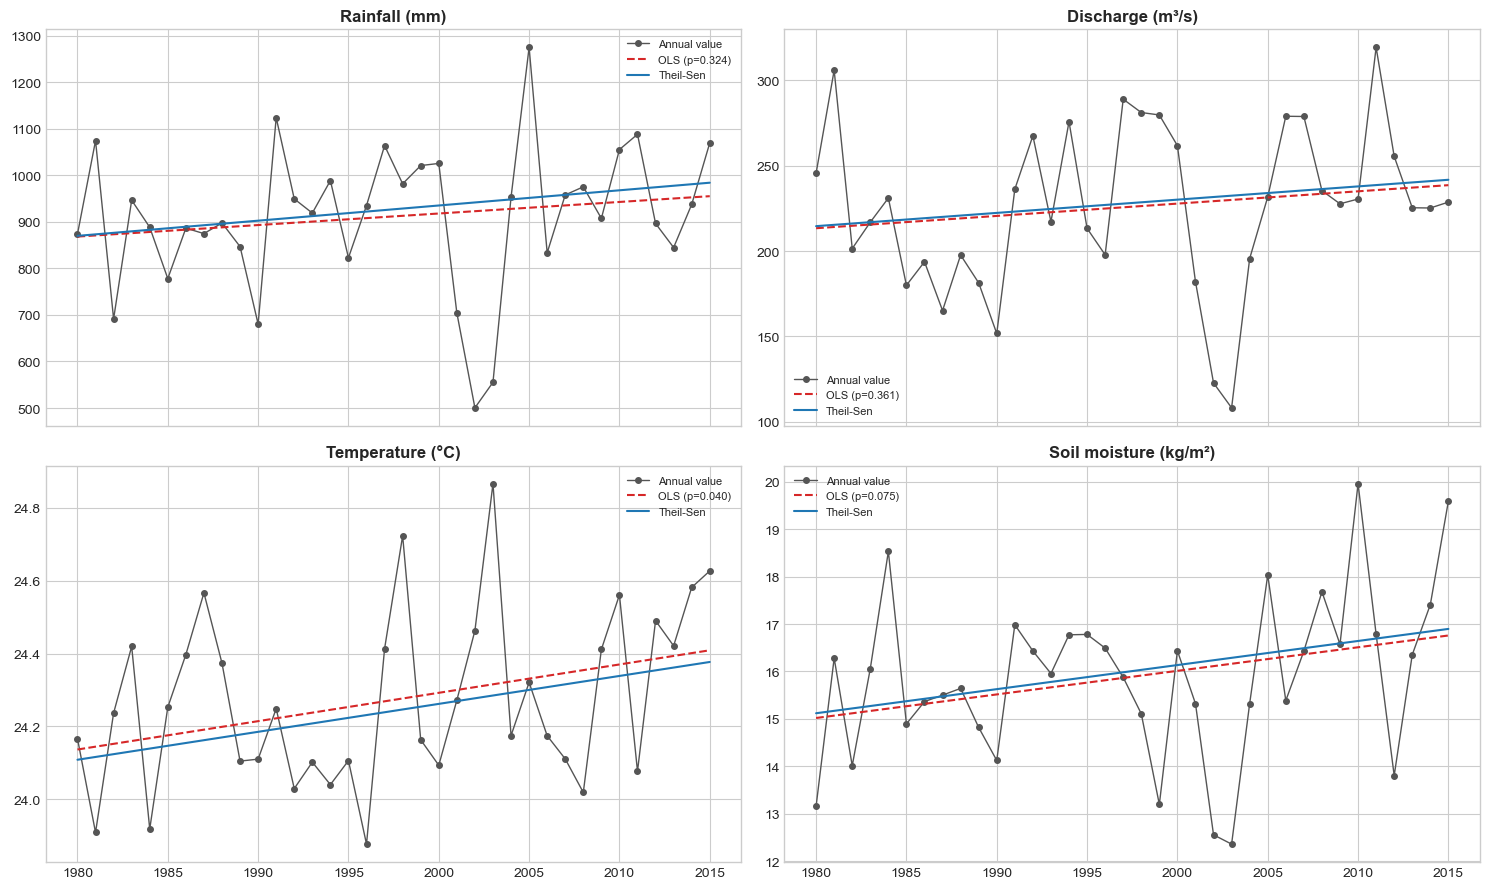

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
for ax, p in zip(axes.ravel(), kd.PARAMS):
    y = annual[p].values
    ols = linregress(years, y); ts = theilslopes(y, years, 0.95)
    ax.plot(years, y, "o-", color="#555555", ms=4, lw=1, label="Annual value")
    ax.plot(years, ols.intercept + ols.slope * years, "--", color="#d62728", label=f"OLS (p={ols.pvalue:.3f})")
    ax.plot(years, ts[1] + ts[0] * years, "-", color="#1f77b4", label="Theil-Sen")
    ax.set_title(kd.LABELS[p], fontweight="bold"); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("02_annual_trends"); plt.show()

### 2.1 Seasonal Mann-Kendall (monthly data) and trends in extremes
Annual means can hide changes that happen only in some months. The seasonal MK test uses the 432 monthly values while respecting the 12-month cycle. We also test the **annual maximum** (largest daily value each year) — climate change often shows up in extremes before it shows up in means.

In [12]:
rows = []
annual_max = daily.resample("YS").max()
for p in kd.PARAMS:
    s = mk.seasonal_test(monthly[p].values, period=12)
    e = mk.original_test(annual_max[p].values)
    rows.append({"variable": p,
                 "Seasonal MK p": s.p, "Seasonal MK trend": s.trend,
                 "Annual-max MK p": e.p, "Annual-max MK trend": e.trend})
extra = pd.DataFrame(rows).set_index("variable")
extra.round(4)

,Seasonal MK p,Seasonal MK trend,Annual-max MK p,Annual-max MK trend
variable,,,,
rainfall_mm,0.2743,no trend,0.5953,no trend
discharge_m3s,0.0201,increasing,0.7437,no trend
temperature_c,0.0000,increasing,0.4871,no trend
soil_moisture_kgm2,0.0099,increasing,0.8809,no trend


In [13]:
full = trend.join(extra)
full.round(5).to_csv(f"{TAB_DIR}/trend_tests.csv", index_label="variable")
full[["OLS p", "MK p", "Hamed-Rao p", "MK p (Holm)", "Seasonal MK p", "Annual-max MK p"]].round(4)

,OLS p,MK p,Hamed-Rao p,MK p (Holm),Seasonal MK p,Annual-max MK p
variable,,,,,,
rainfall_mm,0.3245,0.1450,0.0824,0.2900,0.2743,0.5953
discharge_m3s,0.3605,0.3908,0.4619,0.3908,0.0201,0.7437
temperature_c,0.0398,0.0514,0.0744,0.2058,0.0000,0.4871
soil_moisture_kgm2,0.0752,0.0583,0.0583,0.2058,0.0099,0.8809


### How to interpret the trend table
* **p ≈ 0.05 is not a cliff.** Two tests that disagree about "significant" at p = 0.049 vs 0.051 are telling you the evidence is *borderline*, not that one test is right. Always read the slope and its confidence interval, not just the p-value.
* If **Theil-Sen CI includes 0**, the data cannot rule out "no trend".
* If the **Holm-adjusted p** is no longer < 0.05, the result may not survive multiple-testing correction.
* If the seasonal MK p-value is much smaller than the annual MK p-value, the monthly data carry trend information that annual averaging (only 36 points) lacks — but check that the direction makes physical sense.

### Key findings
* Scale matters, and autocorrelation is severe. The same three-driver regression explains R² = 0.25 of daily, 0.51 of monthly and 0.58 of annual discharge (annual adjusted R² 0.54, only 36 points). The Durbin-Watson statistic is 0.14 at the daily scale and 1.36 at the monthly scale (2 = none), so ordinary OLS p-values would be badly over-confident; all reported errors are HAC-robust.
* Lagged rainfall is the biggest improvement. Adding rainfall lagged 1–2 months raises adjusted R² from 0.501 to 0.652 and lowers AIC from 5190.9 to 5037.7. Adding seasonality terms helps only a little more (adjusted R² 0.663, AIC 5025.8). Residual autocorrelation falls but remains (Durbin-Watson 1.53).
* Coefficients (model M3). Last month's rainfall has the largest effect (+0.98 m³/s per extra mm, 95 % robust CI 0.81–1.14), followed by this month's (+0.71, CI 0.33–1.09) and two months ago (+0.60, CI 0.40–0.80). Temperature has a strong negative association (−26.0 m³/s per °C, CI −32.6 to −19.4) that largely reflects hot months being dry months, not a direct cause. Soil moisture is not significant once lagged rainfall is included (p = 0.14), because it is correlated with rainfall.
* Multicollinearity is moderate. All VIFs are below 5 (highest: soil moisture 4.4), so coefficients are interpretable, though soil moisture's is the least stable.
* Annual trends are not robust. No annual trend survives Holm correction (all adjusted p ≥ 0.21). Temperature is borderline (OLS p = 0.040, Mann-Kendall p = 0.051, Hamed-Rao p = 0.074; slope ≈ 0.008 °C/yr with a Theil-Sen CI that just includes zero). Rainfall, discharge and soil moisture show positive slopes of about 3 % per decade but with wide intervals that include zero.
* Monthly seasonal tests are more sensitive. The seasonal Mann-Kendall test finds increasing temperature (p < 0.001), soil moisture (p = 0.0099) and discharge (p = 0.020), and no rainfall trend (p = 0.27); these remain below 0.05 after Holm correction across the four variables. This test does not correct for autocorrelation, so treat the discharge and soil-moisture results as suggestive. No variable shows a trend in annual maxima (all p > 0.48).

➡️ Next: **`03_time_series_arima.ipynb`** - stationarity, ACF/PACF, ARIMA/SARIMA with proper out-of-sample evaluation.